# UFO reports: timing and reported duration
**Keliang Zhu | IS445 | Homework 5**

I use the course UFO dataset to ask two questions: how are U.S. reports distributed across months and years, and how does reported duration differ among common shapes? The analysis covers 2000–2013, ending before the partial year 2014. These are reports in a collected dataset, not verified events or estimates of population risk.

Source: [course CSV](https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/ufo-scrubbed-geocoded-time-standardized-00.csv).

Run all cells in order with Python 3, pandas, Altair 5, and vl-convert-python. If needed: `%pip install pandas "altair>=5,<6" vl-convert-python`. The notebook downloads the CSV directly from its URL. Outputs go into `../assets/json` and `../assets/pngs` when run from the site's `python_notebooks` folder; elsewhere they go into a local `hw5_exports` folder.

In [1]:
from pathlib import Path
import base64
import calendar
import numpy as np
import pandas as pd
import altair as alt
import vl_convert as vlc
from IPython.display import display

print(f"pandas {pd.__version__}; Altair {alt.__version__}; vl-convert {vlc.__version__}")
DATA_URL = "https://raw.githubusercontent.com/UIUC-iSchool-DataViz/is445_data/main/ufo-scrubbed-geocoded-time-standardized-00.csv"
columns = ["datetime", "city", "state", "country", "shape", "duration_seconds",
           "duration_text", "comments", "date_posted", "latitude", "longitude"]
# This course file has no header: retain its first observation.
raw = pd.read_csv(DATA_URL, header=None, names=columns)
print(f"Source rows: {len(raw):,}")
raw.head(3)

pandas 3.0.6; Altair 5.5.0; vl-convert 1.9.0


Source rows: 80,332


,datetime,city,state,country,shape,duration_seconds,duration_text,comments,date_posted,latitude,longitude
0,10/10/1949 20:30,san marcos,tx,us,cylinder,2700.0,45 minutes,This event took place in early fall around 194...,4/27/2004,29.883056,-97.941111
1,10/10/1949 21:00,lackland afb,tx,NaN,light,7200.0,1-2 hrs,1949 Lackland AFB&#44 TX. Lights racing acros...,12/16/2005,29.384210,-98.581082
2,10/10/1955 17:00,chester (uk/england),NaN,gb,circle,20.0,20 seconds,Green/Orange circular disc over Chester&#44 En...,1/21/2008,53.200000,-2.916667


## Prepare the shared study population
Parse the observation date with the source's explicit date format. Normalize country and shape labels, then retain records labeled `us` with observation years 2000–2013. Missing countries are excluded rather than inferred from coordinates. I count source rows as reports and do not claim that they are distinct physical events. The heatmap includes every shape, including missing and unknown values.

In [2]:
data = raw.copy()
data["observed_at"] = pd.to_datetime(data["datetime"], format="%m/%d/%Y %H:%M", errors="coerce")
data["country"] = data["country"].astype("string").str.strip().str.lower()
data["shape"] = data["shape"].astype("string").str.strip().str.lower()
data["duration_seconds"] = pd.to_numeric(data["duration_seconds"], errors="coerce")
us = data.loc[data["country"].eq("us") & data["observed_at"].dt.year.between(2000, 2013)].copy()
us["year"] = us["observed_at"].dt.year
us["month"] = us["observed_at"].dt.month
print(f"Unparseable dates in source: {data['observed_at'].isna().sum():,}")
print(f"Missing country in source: {data['country'].isna().sum():,}")
print(f"U.S. reports, 2000–2013: {len(us):,}")
assert not us.empty
assert us["year"].between(2000, 2013).all()

Unparseable dates in source: 0
Missing country in source: 9,670
U.S. reports, 2000–2013: 50,849


## Plot 1: reports by month and year
Each rectangle represents a month–year combination. Month and year are ordered categories on the horizontal and vertical axes; color encodes the quantitative report count. A sequential blue scale makes larger counts darker without implying a meaningful midpoint. I group the filtered rows by year and month, count them, and reindex to the complete 14 × 12 grid, filling unobserved combinations with zero. This shows both within-year seasonality and differences between years; it does not normalize for population or reporting effort. Tooltips provide exact counts.

In [3]:
grid = pd.MultiIndex.from_product([range(2000, 2014), range(1, 13)], names=["year", "month"])
monthly = us.groupby(["year", "month"]).size().reindex(grid, fill_value=0).rename("reports").reset_index()
months = list(calendar.month_abbr)[1:]
monthly["month_name"] = monthly["month"].map(dict(enumerate(months, start=1)))
assert monthly["reports"].sum() == len(us)
assert len(monthly) == 14 * 12

plot1 = alt.Chart(monthly).mark_rect(stroke="white", strokeWidth=1).encode(
    x=alt.X("month_name:O", sort=months, title="Month", axis=alt.Axis(labelAngle=0)),
    y=alt.Y("year:O", sort="ascending", title="Year"),
    color=alt.Color("reports:Q", title="Reports", scale=alt.Scale(scheme="blues", zero=True)),
    tooltip=[alt.Tooltip("year:O", title="Year"), alt.Tooltip("month_name:O", title="Month"),
             alt.Tooltip("reports:Q", title="Reports", format=",")]
).properties(width=580, height=370, title="When were UFO reports observed?").configure_view(stroke=None).configure_axis(
    labelFontSize=12, titleFontSize=13
)
plot1

alt.Chart(...)

## Plot 2: duration by common shape
Reported durations are strongly skewed, so I summarize them using medians and the interquartile range (25th to 75th percentiles). I keep only finite, positive durations and named shapes, excluding missing, blank, `unknown`, and `other` categories. I select the eight most frequent remaining shapes over the full study period and keep this set fixed across period filters. Durations are converted from seconds to minutes; no upper cutoff is applied.

For each shape, a horizontal line shows the middle 50% of durations and a dot shows the median. Shape is nominal on the vertical axis; duration is quantitative on a logarithmic horizontal axis. Equal distances on that axis represent equal ratios, not equal added minutes. A single teal color is used because the axis already identifies each shape; color does not encode an additional variable. The intervals describe the data's spread, not uncertainty in the median.

In [4]:
valid_duration = np.isfinite(us["duration_seconds"]) & us["duration_seconds"].gt(0)
named_shape = us["shape"].notna() & ~us["shape"].isin(["", "unknown", "other"])
duration = us.loc[valid_duration & named_shape].copy()
duration["minutes"] = duration["duration_seconds"] / 60
shape_order = duration["shape"].value_counts().head(8).index.tolist()
duration = duration.loc[duration["shape"].isin(shape_order)].copy()
duration["period"] = pd.cut(duration["year"], bins=[1999, 2004, 2009, 2013],
                            labels=["2000–2004", "2005–2009", "2010–2013"]).astype(str)

def summarize(frame):
    return frame.groupby("shape")["minutes"].agg(
        q1=lambda s: s.quantile(.25), median="median", q3=lambda s: s.quantile(.75), reports="size"
    ).reset_index()

all_periods = summarize(duration).assign(period="All years")
parts = [all_periods]
for period, group in duration.groupby("period"):
    parts.append(summarize(group).assign(period=period))
summary = pd.concat(parts, ignore_index=True)
assert (summary["q1"] > 0).all()
assert ((summary["q1"] <= summary["median"]) & (summary["median"] <= summary["q3"])).all()
assert all_periods["reports"].sum() == len(duration)
print(f"Excluded invalid/nonpositive durations in shared cohort: {(~valid_duration).sum():,}")
print(f"Excluded missing/unknown/other shape labels in shared cohort: {(~named_shape).sum():,}")
print(f"Reports retained for the eight-shape duration comparison: {len(duration):,}")
print("Fixed shape order:", ", ".join(shape_order))
summary

Excluded invalid/nonpositive durations in shared cohort: 0


Excluded missing/unknown/other shape labels in shared cohort: 7,719
Reports retained for the eight-shape duration comparison: 35,417
Fixed shape order: light, triangle, circle, fireball, sphere, disk, oval, formation


,shape,q1,median,q3,reports,period
0,circle,0.666667,3.000000,10.0,4979,All years
1,disk,0.500000,3.000000,10.0,2490,All years
2,fireball,0.166667,2.000000,5.0,4285,All years
3,formation,0.750000,3.000000,10.0,1614,All years
4,light,0.500000,3.000000,15.0,11254,All years
5,oval,0.500000,3.000000,10.0,2358,All years
6,sphere,0.500000,3.000000,10.0,3408,All years
7,triangle,0.500000,2.583333,8.0,5029,All years
8,circle,0.500000,3.000000,15.0,1078,2000–2004
9,disk,0.750000,4.000000,15.0,849,2000–2004


In [5]:
period_choice = alt.param(
    name="period_choice", value="All years",
    bind=alt.binding_select(options=["All years", "2000–2004", "2005–2009", "2010–2013"], name="Period: ")
)
# Fix both axes across selections so filtering does not change the visual scale.
x_domain = [float(summary["q1"].min()) / 1.4, float(summary["q3"].max()) * 1.4]
base = alt.Chart(summary).transform_filter(alt.datum.period == period_choice).encode(
    y=alt.Y("shape:N", sort=shape_order, title="Reported shape"),
    tooltip=[alt.Tooltip("shape:N", title="Shape"), alt.Tooltip("period:N", title="Period"),
             alt.Tooltip("reports:Q", title="Reports", format=","),
             alt.Tooltip("q1:Q", title="25th percentile (min)", format=".2f"),
             alt.Tooltip("median:Q", title="Median (min)", format=".2f"),
             alt.Tooltip("q3:Q", title="75th percentile (min)", format=".2f")]
)
interval = base.mark_rule(strokeWidth=5, color="#197c80", opacity=.45).encode(
    x=alt.X("q1:Q", title="Reported duration (minutes, log scale)",
            scale=alt.Scale(type="log", domain=x_domain, nice=False), axis=alt.Axis(format="~g", values=[.1, .2, .5, 1, 2, 5, 10, 20])),
    x2="q3:Q"
)
median = base.mark_point(filled=True, size=100, color="#197c80", opacity=1).encode(x=alt.X("median:Q", scale=alt.Scale(type="log", domain=x_domain, nice=False)))
plot2 = (interval + median).add_params(period_choice).properties(
    width=580, height=300, title="How long did reports of different shapes last?"
).configure_view(stroke=None).configure_axis(labelFontSize=12, titleFontSize=13)
plot2

alt.LayerChart(...)

## Interaction and interpretation
Use the **Period** dropdown to compare all years with 2000–2004, 2005–2009, or 2010–2013. The filter replaces the duration summaries for every shape, while fixed shape order and axis limits make comparisons easier to follow. This is a data filter beyond pan/zoom. Hover over a dot or interval to inspect the sample size and quartiles. The heatmap has its own count tooltips; the charts are not linked.

Neither visualization establishes whether a report was accurate. Reporting habits, database coverage, and the availability of witnesses may affect the patterns. The periods have unequal lengths, so their sample sizes should not be read as directly comparable reporting rates. Shape labels and durations are supplied by reporters; the text duration and numeric duration can also disagree. This analysis consistently uses the dataset's numeric seconds field.

In [6]:
peak = monthly.loc[monthly["reports"].idxmax()]
print(f"Highest month-year count: {peak['month_name']} {peak['year']}, {peak['reports']:,} reports.")
print("Full-period duration medians (minutes):")
print(all_periods[["shape", "median", "reports"]].sort_values("median").to_string(index=False))

Highest month-year count: Jul 2013, 775 reports.
Full-period duration medians (minutes):
    shape   median  reports
 fireball 2.000000     4285
 triangle 2.583333     5029
     disk 3.000000     2490
   circle 3.000000     4979
formation 3.000000     1614
    light 3.000000    11254
     oval 3.000000     2358
   sphere 3.000000     3408


## Export for Jekyll
Both charts are saved as Vega-Lite JSON. Each JSON embeds only the aggregated plotting data, so the webpage does not have to download all 80,332 source records. PNG exports provide static previews and a GitHub-readable notebook fallback; the webpage uses the interactive JSON.

Saved hw5_ufo_monthly.json and hw5_ufo_monthly.png


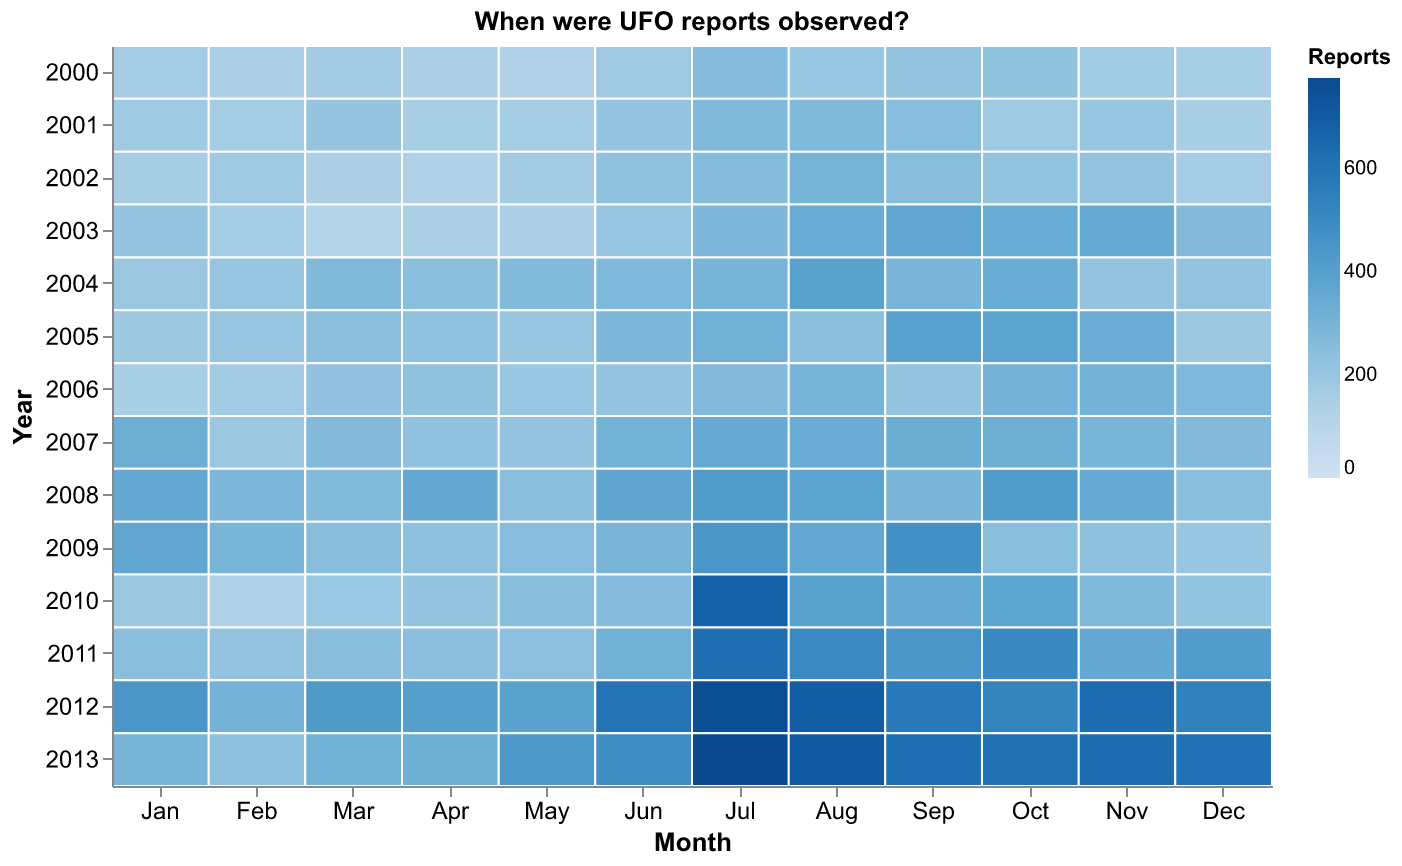

Saved hw5_ufo_duration.json and hw5_ufo_duration.png


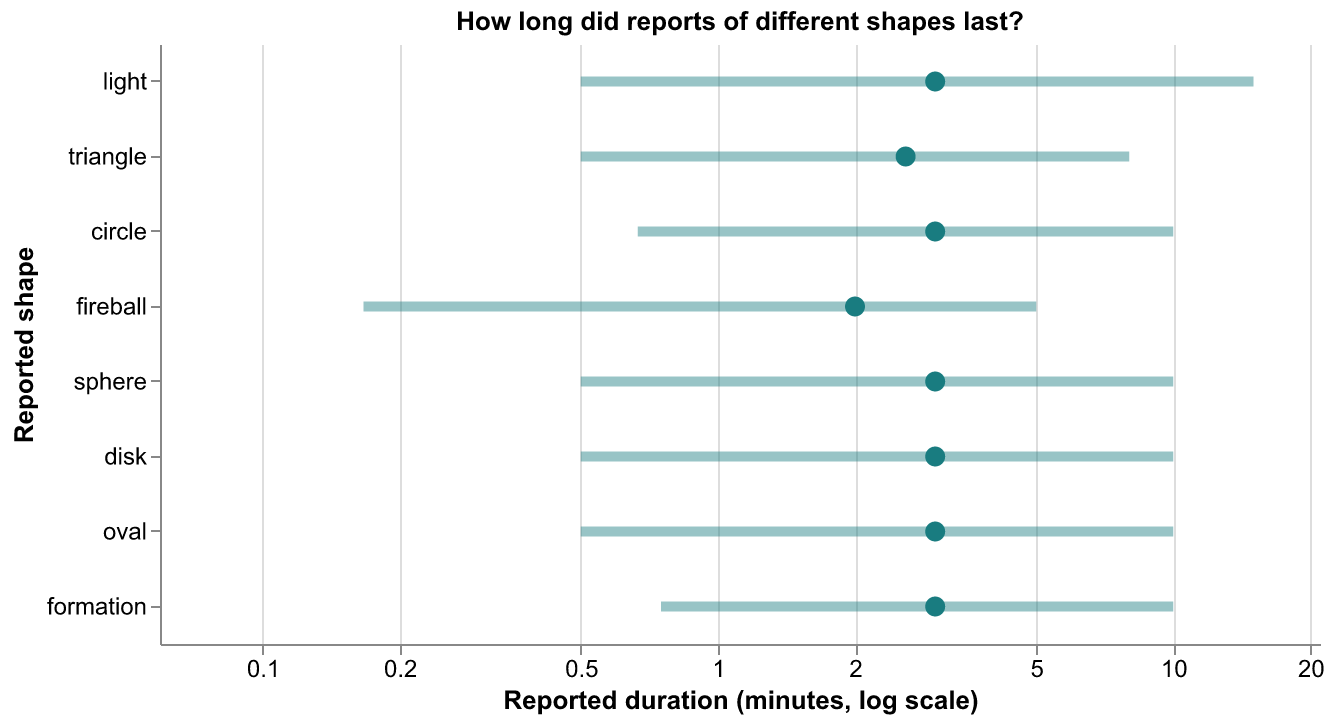

In [7]:
cwd = Path.cwd()
site_root = cwd.parent if cwd.name == "python_notebooks" and (cwd.parent / "_config.yml").exists() else None
output_root = site_root / "assets" if site_root else cwd / "hw5_exports"
json_dir = output_root / "json"
png_dir = output_root / "pngs"
json_dir.mkdir(parents=True, exist_ok=True)
png_dir.mkdir(parents=True, exist_ok=True)
for name, chart in [("hw5_ufo_monthly", plot1), ("hw5_ufo_duration", plot2)]:
    chart.save(str(json_dir / f"{name}.json"))
    png = vlc.vegalite_to_png(chart.to_dict(), scale=2)
    (png_dir / f"{name}.png").write_bytes(png)
    print(f"Saved {name}.json and {name}.png")
    # One rich output supports interactive Jupyter rendering and static GitHub rendering.
    display({"application/vnd.vegalite.v5+json": chart.to_dict(),
             "image/png": base64.b64encode(png).decode("ascii"),
             "text/plain": name}, raw=True)